# 08 – Location check: is the location useful for the model?
**Input:** `food_final.csv` (from `06_Merge.ipynb`)  **Output:** `location_features.csv`

Before we create the dummy variables for the model, we check if the **location** of a business is related to failing. We try two ways: (A) the **Zip code**, and (B) **areas found with k-means clustering** on Latitude and Longitude (Chapter 11). For both we use the chi-square test and Cramér's V, as in `07_Tests.ipynb`. The location is known before the inspection, so it is allowed as a model feature (no leakage).

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

pandas and numpy for the tables, scipy.stats for the chi-square test, matplotlib for the plots, and `KMeans` from scikit-learn for the clustering (Chapter 11).

In [2]:
final = pd.read_csv('food_final.csv')
print(final.shape)
final[['Inspection ID', 'Business_ID', 'Zip', 'Latitude', 'Longitude', 'Period', 'Fail']].head()

(126787, 53)


,Inspection ID,Business_ID,Zip,Latitude,Longitude,Period,Fail
0,2569129,2882090_CRUMBL COOKIES,60614.0,41.924208,-87.646818,Post,0
1,2569114,2341106_STARBUCKS COFFEE #20797,60618.0,41.947947,-87.688440,Post,0
2,2569125,2608949_LITTLE EXPLORERS LEARNING ACADEMY INC.,60638.0,41.792333,-87.788146,Post,0
3,2569122,86324_BOSTON MARKET #2520,60657.0,41.936721,-87.668703,Post,1
4,2569126,2589615_TODD APPEL BAR AND COCKTAIL,60659.0,41.988060,-87.703704,Post,0


There are **126787** rows and **53** columns. The output values shows some values of the location columns we use, together with Inspection ID, Business_ID, Period and the target Fail.

In [3]:
def cramers_v(table):
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.values.sum()
    k = min(table.shape) - 1
    return np.sqrt(chi2 / (n * k))

The same Cramér's V function as in `07_Tests.ipynb` (0 = no relation, 1 = perfect relation; below 0.1 is usually called negligible).

In [4]:
final[['Zip', 'Latitude', 'Longitude']].isnull().sum()

Zip            1
Latitude     455
Longitude    455
dtype: int64

Only **1** row has a missing Zip, and **455** rows have no Latitude and Longitude. The row without a Zip goes to the group "Other" and the rows without coordinates get the area -1 ("Unknown") below, so we do not lose any inspection.

## A. Zip code

In [5]:
# Chicago Zip codes start with 606; the others (outside Chicago or missing) become 'Other'
final['Zip_Group'] = 'Other'
chicago = final['Zip'].notnull() & final['Zip'].astype(str).str.startswith('606')
final.loc[chicago, 'Zip_Group'] = final.loc[chicago, 'Zip'].astype(int).astype(str)

# Zip codes with fewer than 100 inspections are too small to say anything; they also go to 'Other'
zip_counts = final['Zip_Group'].value_counts()
small = zip_counts[zip_counts < 100].index
final.loc[final['Zip_Group'].isin(small), 'Zip_Group'] = 'Other'

print('Number of Zip groups:', final['Zip_Group'].nunique())
final['Zip_Group'].value_counts().head(10)

Number of Zip groups: 58


Zip_Group
60614    4716
60647    4543
60657    4279
60611    4072
60608    3929
60618    3916
60607    3855
60622    3694
60640    3687
60625    3590
Name: count, dtype: int64

There are 58 Zip group with the largest one, 60614, having a total of 4716 inspections. Chicago Zip codes start with 606 (see `05_Risk_Location.ipynb`); the rest and the very small Zip codes are grouped into "Other".

In [6]:
zip_fail = final.groupby('Zip_Group')['Fail'].agg(['count', 'mean']).sort_values('mean')
print('Lowest fail rates:')
print(zip_fail.head(5).round(3))
print()
print('Highest fail rates:')
print(zip_fail.tail(5).round(3))

Lowest fail rates:
           count   mean
Zip_Group              
60666       1852  0.134
60601       2227  0.137
60654       2944  0.142
60611       4072  0.143
60604        838  0.149

Highest fail rates:
           count   mean
Zip_Group              
60636       1252  0.290
60619       2369  0.294
60628       2226  0.299
60621       1133  0.299
60620       2377  0.305


The Zip group with the **lowest** fail rate is **60666** (13.4%, this is the O'Hare airport area) and the **highest** is **60620** (30.5%). The highest fail rate is more than **twice** the lowest, so the location seems to matter; the chi-square test below checks if this difference is real.

In [7]:
table_zip = pd.crosstab(final['Zip_Group'], final['Fail'])
chi2, p, dof, expected = stats.chi2_contingency(table_zip)
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p:.3e}, min expected = {expected.min():.0f}')
print(f"Cramer's V = {cramers_v(table_zip):.3f}")

Chi-square = 1322.10, df = 57, p-value = 5.327e-239, min expected = 51
Cramer's V = 0.102


**H0:** the fail rate is the same in every Zip group. **H1:** it is different. Assumptions: categorical variables, every expected count ≥ 5 (we removed the small Zip codes for this), inspections not fully independent (limitation, as in `07_Tests`). Result: χ² = 1322.10, df = 57, p ≈ 5.3 × 10⁻²³⁹ (smallest expected count: 51), so we **reject H0**: the fail rate differs between the Zip groups. Cramér's V = **0.102**, a **small** effect. So the Zip code is related to failing, but it explains only a small part of it; with 126,787 inspections even small differences become significant.

In [8]:
for period in ['Pre', 'Post']:
    part = final[final['Period'] == period]
    table = pd.crosstab(part['Zip_Group'], part['Fail'])
    print(f"{period}: Cramer's V = {cramers_v(table):.3f}")

Pre: Cramer's V = 0.115
Post: Cramer's V = 0.123


Is the Zip effect the same before and after the change? **Pre:** Cramer's V = 0.115, **Post:** Cramer's V = 0.123. The effect is quite similar in Pre and Post, the location can be counted as a **stable** feature: it does not change with the new food code, so it should not make the model worse after 2018.

## B. Areas with k-means clustering (Chapter 11)

In [9]:
# one row per business (a business that is inspected many times should not count many times),
# only Pre businesses, because the model will be trained on Pre data
pre_places = final[final['Period'] == 'Pre'].drop_duplicates('Business_ID')
pre_places = pre_places.dropna(subset=['Latitude', 'Longitude'])
coords = pre_places[['Latitude', 'Longitude']]
print('Businesses used for the clustering:', len(coords))

Businesses used for the clustering: 17819


The number of businesses after dropping the ones with missing Longitude and Latitude is 17819. We cluster **businesses**, not inspections, and only those from the Pre period, so nothing from the test period (Post) is used to build the areas.

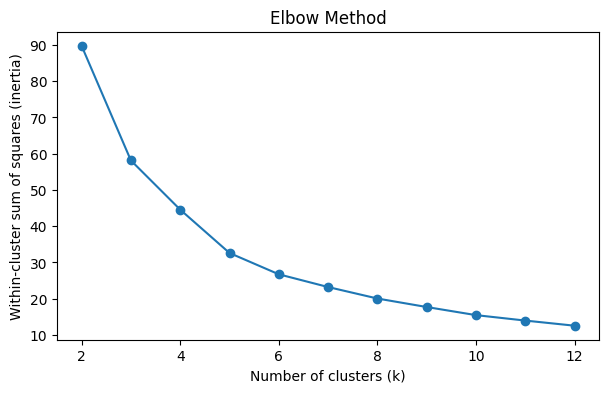

In [10]:
inertias = []
k_values = range(2, 13)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(coords)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares (inertia)')
plt.show()

**Elbow method:** the inertia (within-cluster sum of squares) always goes down when k grows; we look for the "knee", where adding one more cluster does not help much any more. Here we chose k (`best_k`) to be 5.

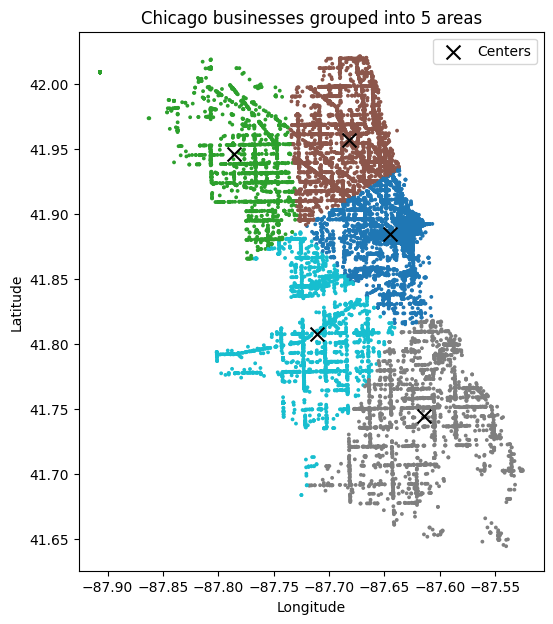

In [11]:
best_k = 5

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans.fit(coords)

plt.figure(figsize=(6, 7))
plt.scatter(coords['Longitude'], coords['Latitude'], c=kmeans.labels_, cmap='tab10', s=3)
plt.scatter(kmeans.cluster_centers_[:, 1], kmeans.cluster_centers_[:, 0], c='black', marker='x', s=100, label='Centers')
plt.title(f'Chicago businesses grouped into {best_k} areas')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()

The map of the businesses, coloured by area (the black crosses are the cluster centers). The areas separation resembles Near South, Near West and Lower West Side, Loop, Near North and West Town areas.

In [12]:
# give every inspection its area; inspections without coordinates get -1 (Unknown)
final['Location_Cluster'] = -1
has_xy = final['Latitude'].notnull() & final['Longitude'].notnull()
final.loc[has_xy, 'Location_Cluster'] = kmeans.predict(final.loc[has_xy, ['Latitude', 'Longitude']])

final.groupby('Location_Cluster')['Fail'].agg(['count', 'mean']).round(3)

,count,mean
Location_Cluster,,
-1,455,0.235
0,42436,0.192
1,15206,0.221
2,34354,0.236
3,18415,0.266
4,15921,0.235


Number of inspections and fail rate per area (-1 = no coordinates, 455 inspections). The fail rate goes from **19.2%** (area 0, the largest area with 42,436 inspections) to **26.6%** (area 3). The difference between the areas (about 7 percentage points) is much smaller than between the Zip codes (13.4% to 30.5%), because 5 big areas mix neighbourhoods with high and low fail rates.

In [13]:
table_cl = pd.crosstab(final['Location_Cluster'], final['Fail'])
chi2, p, dof, expected = stats.chi2_contingency(table_cl)
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p:.3e}, min expected = {expected.min():.0f}')
print(f"Cramer's V = {cramers_v(table_cl):.3f}")

for period in ['Pre', 'Post']:
    part = final[final['Period'] == period]
    table = pd.crosstab(part['Location_Cluster'], part['Fail'])
    print(f"{period}: Cramer's V = {cramers_v(table):.3f}")

Chi-square = 470.54, df = 5, p-value = 1.821e-99, min expected = 102
Cramer's V = 0.061
Pre: Cramer's V = 0.041
Post: Cramer's V = 0.075


**H0:** the fail rate is the same in every area. **H1:** it is different. Result: χ² = 470.54, df = 5, p ≈ 1.8 × 10⁻⁹⁹ (smallest expected count: 102), so we **reject H0**: the fail rate differs between the areas. Cramér's V = **0.061**, a **very small** effect, smaller than for the Zip groups (0.102). **Pre:** V = 0.041, **Post:** V = 0.075, so the effect after the change is almost **double** the effect before. So the k-means areas are less related to failing than the Zip codes, and their effect is also **less stable** between Pre and Post.

## Decision

| | Zip groups | k-means areas (k = 5) |
| --- | --- | --- |
| Cramér's V (all) | **0.102** | 0.061 |
| Pre / Post | 0.115 / 0.123 (stable) | 0.041 / 0.075 (not stable) |
| Dummy columns needed | 57 (58 groups, one dropped) | 5 (6 groups, one dropped) |

Both are above the negligible level (about 0.05), so the location carries some information. The **Zip groups are clearly better**: their effect is larger and almost the **same before and after the change**, so they should help the model in both periods. The k-means areas are too big (they mix neighbourhoods with high and low fail rates) and their effect changes between Pre and Post. **We use `Zip_Group` as dummy variables in the model.** 57 dummy columns are not a problem for logistic regression or a decision tree with about 70,000 training rows; for KNN, which uses distances, we will check if so many 0/1 columns make the results worse.

In [14]:
final[['Inspection ID', 'Zip_Group', 'Location_Cluster']].to_csv('location_features.csv', index=False)
print('Saved:', final[['Inspection ID', 'Zip_Group', 'Location_Cluster']].shape)

Saved: (126787, 3)


We save the two location columns with Inspection ID, so they can be merged with `food_final.csv` when we prepare the model data.